In [1]:
import scanpy as sc

rna = sc.read_h5ad("Ma-2020-RNA.h5ad")
atac = sc.read_h5ad("Ma-2020-ATAC.h5ad")

In [2]:
print(rna.shape)
print(atac.shape)

print((rna.obs_names == atac.obs_names).all())

(32231, 21478)
(32231, 340341)
True


In [3]:
print(rna)
print(atac)

print(rna.obs.columns)
print(atac.obs.columns)

print(rna.obsm.keys())
print(atac.obsm.keys())

print(rna.uns.keys())
print(atac.uns.keys())

AnnData object with n_obs × n_vars = 32231 × 21478
    obs: 'domain', 'protocol', 'dataset', 'cell_type', 'batch'
    var: 'chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb', 'blockCount', 'blockSizes', 'blockStarts', 'gene_id', 'gene_type', 'mgi_id', 'havana_gene', 'tag', 'genome', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
AnnData object with n_obs × n_vars = 32231 × 340341
    obs: 'domain', 'protocol', 'dataset', 'cell_type', 'batch'
    var: 'chrom', 'chromStart', 'chromEnd', 'genome', 'n_counts'
Index(['domain', 'protocol', 'dataset', 'cell_type', 'batch'], dtype='object')
Index(['domain', 'protocol', 'dataset', 'cell_type', 'batch'], dtype='object')
KeysView(AxisArrays with keys: )
KeysView(AxisArrays with keys: )
dict_keys(['hvg'])
odict_keys([])


In [5]:
print(list(rna.obs['cell_type'].unique()))

['Dermal Fibroblast', 'Dermal Papilla', 'TAC-1', 'IRS', 'Basal', 'K6+ Bulge/Companion Layer', 'Medulla', 'alow CD34+ bulge', 'Isthmus', 'ORS', 'Infundibulum', 'Spinous', 'ahigh CD34+ bulge', 'TAC-2', 'Macrophage DC', 'Endothelial', 'Dermal Sheath', 'Sebaceous Gland', 'Granular', 'Hair Shaft-Cuticle/Cortex', 'Schwann Cell', 'Melanocyte']


In [4]:
hair_lineage = [
    "TAC-1",
    "TAC-2",
    "IRS",
    "Hair Shaft-Cuticle/Cortex",
    "Medulla",
]

mask = rna.obs["cell_type"].isin(hair_lineage)
rna_hair = rna[mask].copy()
atac_hair = atac[mask].copy()

rna_hair

AnnData object with n_obs × n_vars = 7197 × 21478
    obs: 'domain', 'protocol', 'dataset', 'cell_type', 'batch'
    var: 'chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb', 'blockCount', 'blockSizes', 'blockStarts', 'gene_id', 'gene_type', 'mgi_id', 'havana_gene', 'tag', 'genome', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc
import decipher as dc

adata = rna_hair

/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
import numpy as np

X = adata.X

print("min:", X.min())
print("max:", X.max())

# check if values are integers
is_integer_like = np.allclose(X.data, np.round(X.data))
print("integer-like:", is_integer_like)

min: 0.0
max: 1803.0
integer-like: True


In [7]:
adata.layers["counts"] = adata.X.copy() 
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True)

print(f"Post-filtering: {adata.n_vars} genes remaining.")

Post-filtering: 2000 genes remaining.


In [8]:
adata.X = adata[:, adata.var_names].layers["counts"].copy()

2026-08-05 04:40:53,193 | INFO : Early stopping has been triggered.) | val ll: 253.71:   6%| | 55/1000 [03:17<5
2026-08-05 04:40:53,285 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-08-05 04:40:53,286 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-08-05 04:40:53,296 | INFO : Saving decipher model with run_id 2026-08-05-04-40-53-tractable-coral-optical.


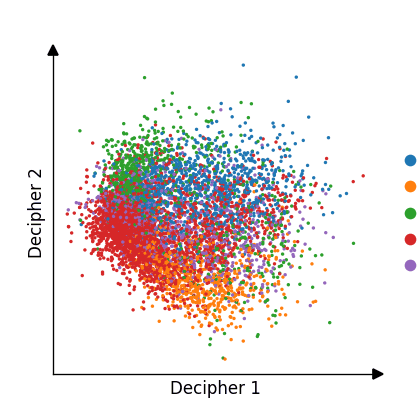

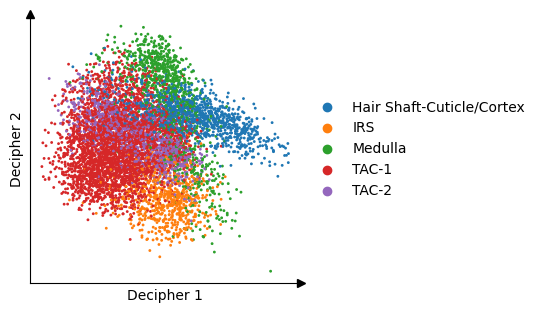

In [9]:
import matplotlib

decipher_config = dc.tl.DecipherConfig(early_stopping_patience=10) # optional Decipher config

d1, val1 = dc.tl.decipher_train(
    adata, decipher_config, plot_kwargs={"color": "cell_type"}, plot_every_k_epochs=5
)

In [10]:
hair_order = [
    "TAC-1",
    "TAC-2",
    "IRS",
    "Hair Shaft-Cuticle/Cortex",
    "Medulla",
]

dc.tl.decipher_rotate_space(
    adata,
    v1_col="cell_type",
    v1_order=hair_order,
)

2026-08-05 04:40:59,854 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-08-05 04:40:59,855 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


In [11]:
%matplotlib inline

2026-08-05 04:41:02,950 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-08-05 04:41:02,951 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-08-05 04:41:17,958 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 1.0.
/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/decipher/tools/trajectory_inference.py:225: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(
2026-08-05 04:41:20,120 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.


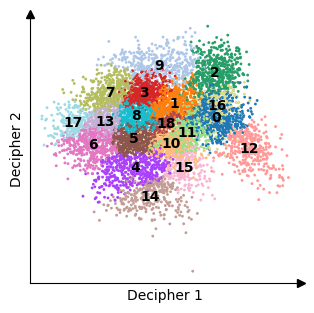

In [12]:
dc.tl.cell_clusters(adata)
dc.pl.decipher(adata, ["decipher_clusters"], legend_loc="on data");

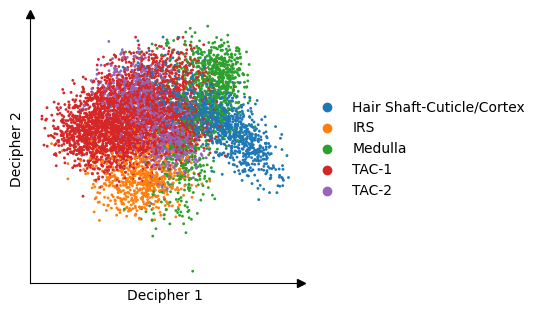

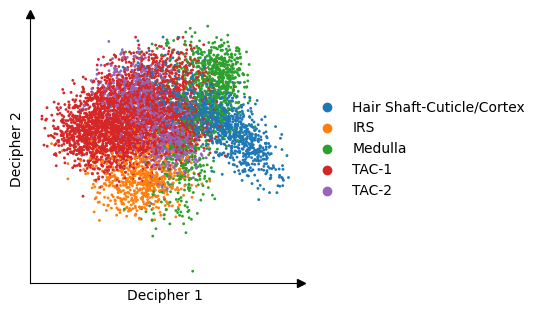

In [13]:
dc.pl.decipher(adata, ["cell_type"])

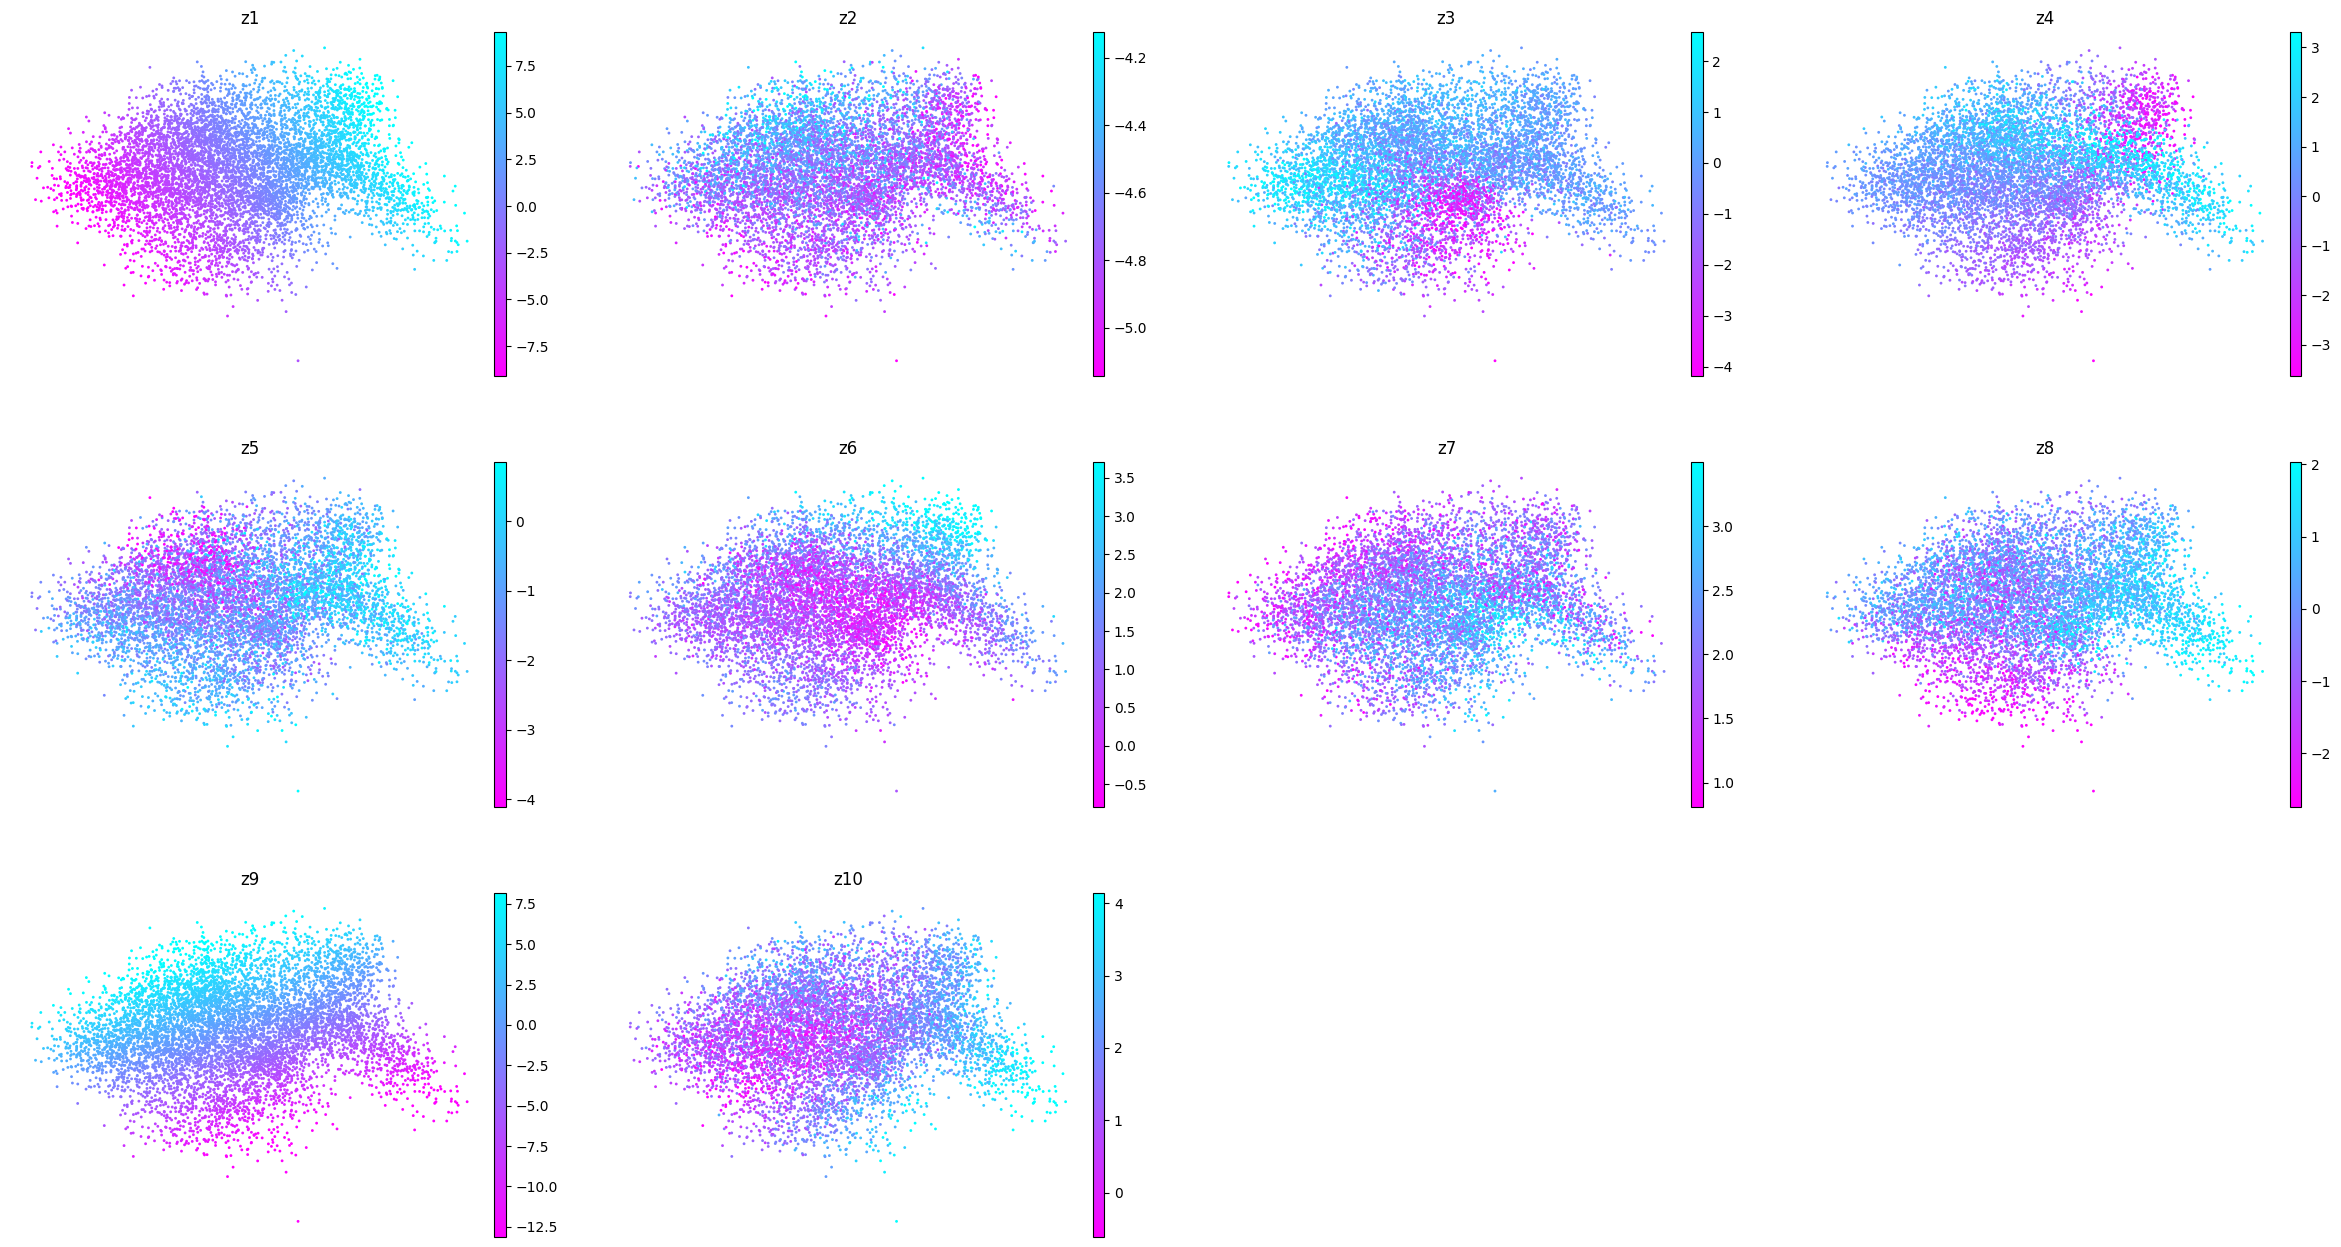

In [14]:
dc.pl.decipher_z(adata);

In [16]:
adata.write("paired_decipher_outputs2/decipher_run_full.h5ad")

np.savez(
    "paired_decipher_outputs2/decipher_embeddings.npz",
    v=adata.obsm["decipher_v"],
    z=adata.obsm["decipher_z"]
)